# 01 - Car Insurance Modelling (claim frequency)
**Topic:** Regression  |  **Reference:** "Car Insurance Modelling using Python" (amanxai.com, Jan 2024)

**Goal.** Predict how many claims a policy will produce per year of cover, so a price can be set per risk.
**Why this is not an ordinary regression.** The target is a *count* (0, 1, 2, ...) and policies are observed for different lengths of time (`Exposure`, in years). A plain least-squares model on the count ignores both facts.

**What the reference does:** a Poisson GLM (statsmodels) on a small 1,000-row file with 3 predictors (it looks synthetic; I could not rerun it because its data file is no longer online), no exposure, no hold-out score.
**What this notebook does differently:** real data (678,013 French motor policies, `freMTPL2freq`), exposure handled properly, four models (constant, two Poisson GLMs, boosting) scored on a hold-out set with the Poisson deviance, and a check of whether the ranking is useful (lift by decile).

## 1. Libraries and data

In [1]:
import warnings, os, json, joblib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, SplineTransformer, StandardScaler
from sklearn.linear_model import PoissonRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_poisson_deviance
import statsmodels.api as sm
sns.set_theme(style="whitegrid", context="notebook")
os.makedirs("model", exist_ok=True)

cache = "../_data/freMTPL2freq.csv"
if os.path.exists(cache):
    raw = pd.read_csv(cache)
else:
    raw = fetch_openml(data_id=41214, as_frame=True, parser="auto").frame
    raw.to_csv(cache, index=False)
raw["VehGas"] = raw["VehGas"].astype(str).str.strip("'")
print(raw.shape)
raw.head()

(678013, 12)


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1.0,1,0.10,D,5,0,55,50,B12,Regular,1217,R82
1,3.0,1,0.77,D,5,0,55,50,B12,Regular,1217,R82
2,5.0,1,0.75,B,6,2,52,50,B12,Diesel,54,R22
3,10.0,1,0.09,B,7,0,46,50,B12,Diesel,76,R72
4,11.0,1,0.84,B,7,0,46,50,B12,Diesel,76,R72


**Columns.** `ClaimNb` claims during the period | `Exposure` fraction of a year insured | `Area` (A rural ... F urban centre) | `VehPower`, `VehAge`, `DrivAge` | `BonusMalus` (100 = no history, lower = better record) | `VehBrand`, `VehGas` | `Density` inhabitants per km2 | `Region`.

## 2. Look at the data before touching it

In [2]:
print(raw.isna().sum().sum(), "missing values")
print(raw[["ClaimNb", "Exposure", "VehAge", "DrivAge", "BonusMalus"]].describe().round(2).T)
print("\nClaimNb counts:\n", raw["ClaimNb"].value_counts().sort_index())
print("\nExposure > 1 year:", (raw["Exposure"] > 1).sum(), "rows | policies with 5+ claims:", (raw["ClaimNb"] >= 5).sum())

0 missing values
               count   mean    std   min    25%    50%    75%     max
ClaimNb     678013.0   0.05   0.24   0.0   0.00   0.00   0.00   16.00
Exposure    678013.0   0.53   0.36   0.0   0.18   0.49   0.99    2.01
VehAge      678013.0   7.04   5.67   0.0   2.00   6.00  11.00  100.00
DrivAge     678013.0  45.50  14.14  18.0  34.00  44.00  55.00  100.00
BonusMalus  678013.0  59.76  15.64  50.0  50.00  50.00  64.00  230.00

ClaimNb counts:
 ClaimNb
0     643953
1      32178
2       1784
3         82
4          7
5          2
6          1
8          1
9          1
11         3
16         1
Name: count, dtype: int64

Exposure > 1 year: 1224 rows | policies with 5+ claims: 9


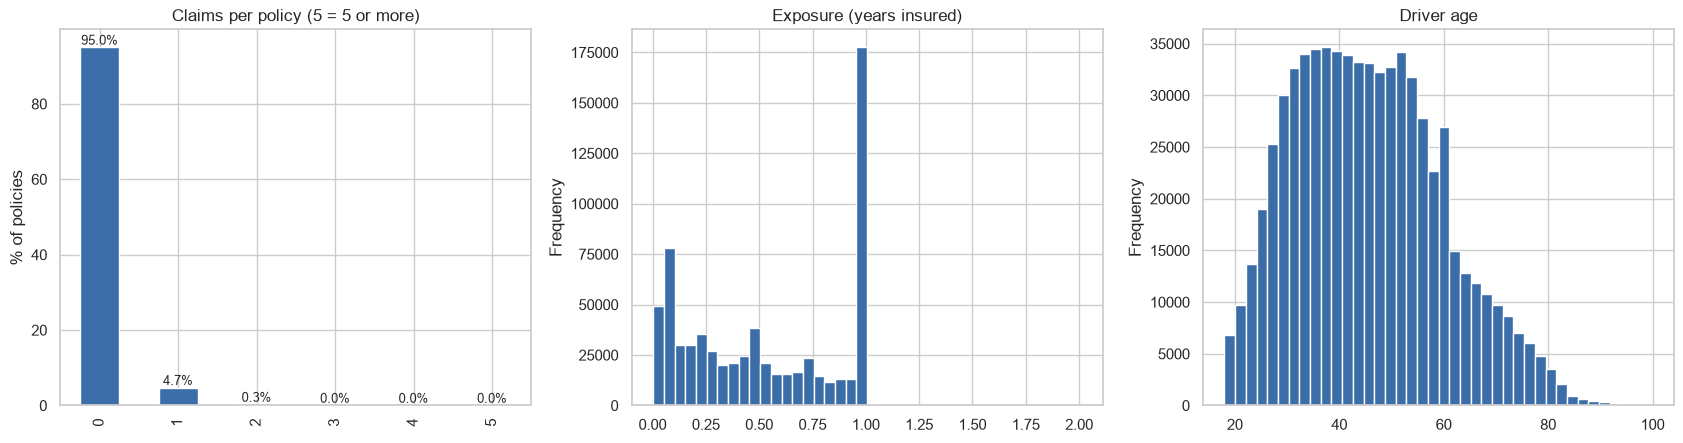

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
raw["ClaimNb"].clip(upper=5).value_counts(normalize=True).sort_index().mul(100).plot.bar(ax=ax[0], color="#3b6ea8")
ax[0].set_title("Claims per policy (5 = 5 or more)"); ax[0].set_ylabel("% of policies"); ax[0].set_xlabel("")
for p in ax[0].patches: ax[0].annotate(f"{p.get_height():.1f}%", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom", fontsize=9)
raw["Exposure"].plot.hist(bins=40, ax=ax[1], color="#3b6ea8"); ax[1].set_title("Exposure (years insured)"); ax[1].set_xlabel("")
raw["DrivAge"].plot.hist(bins=40, ax=ax[2], color="#3b6ea8"); ax[2].set_title("Driver age"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

**Reading it.** About 95% of policies have no claim, so the target is mostly zeros: a count model is the natural choice. Exposure is far from "one year for everybody", so a policy insured 3 months has fewer chances to claim; we model **claims per year of exposure** and weight by exposure.

## 3. Cleaning (documented decisions)
Following the usual practice for this data set: cap `ClaimNb` at 4 (a handful of extreme counts), cap `Exposure` at 1 year (longer values are probably data errors for a one-year contract: I assumed this and did not verify it against the data documentation), cap `VehAge` at 20, `VehPower` at 9, `BonusMalus` at 150, `DrivAge` at 90. Capping is a judgement: it keeps a few extreme rows from steering the fit.

In [4]:
df = raw.copy()
df["ClaimNb"] = df["ClaimNb"].clip(upper=4)
df["Exposure"] = df["Exposure"].clip(upper=1)
df["VehAge"] = df["VehAge"].clip(upper=20)
df["VehPower"] = df["VehPower"].clip(upper=9)
df["BonusMalus"] = df["BonusMalus"].clip(upper=150)
df["DrivAge"] = df["DrivAge"].clip(upper=90)
df["LogDensity"] = np.log(df["Density"])
df["Freq"] = df["ClaimNb"] / df["Exposure"]
print("overall claim frequency: %.4f claims per policy-year" % (df["ClaimNb"].sum() / df["Exposure"].sum()))

overall claim frequency: 0.1006 claims per policy-year


## 4. Visualise the target against each risk factor

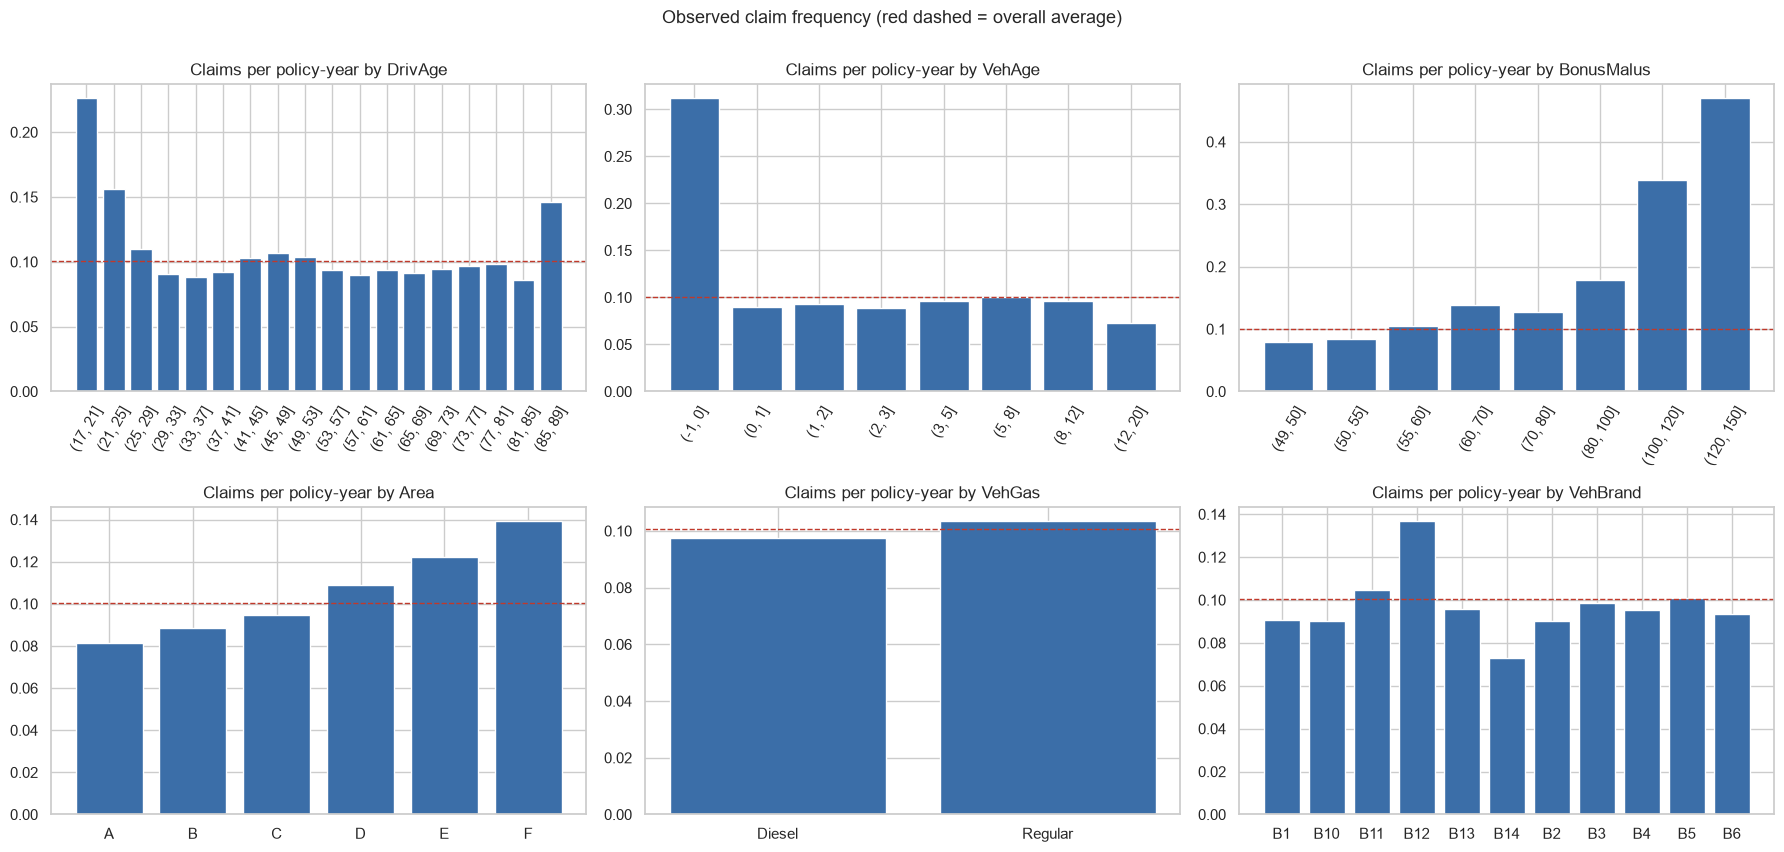

In [5]:
def freq_by(col, bins=None):
    g = df.assign(b=pd.cut(df[col], bins) if bins is not None else df[col]).groupby("b", observed=True)
    return (g["ClaimNb"].sum() / g["Exposure"].sum()), g["Exposure"].sum()

fig, ax = plt.subplots(2, 3, figsize=(18, 8.5))
for a, (col, bins) in zip(ax.ravel(), [("DrivAge", list(range(17, 91, 4))), ("VehAge", [-1,0,1,2,3,5,8,12,20]), ("BonusMalus", [49,50,55,60,70,80,100,120,150]),
                                       ("Area", None), ("VehGas", None), ("VehBrand", None)]):
    f, e = freq_by(col, bins)
    f.index = f.index.astype(str)
    a.bar(f.index, f.values, color="#3b6ea8"); a.set_title(f"Claims per policy-year by {col}"); a.tick_params(axis="x", rotation=60 if bins else 0)
    a.axhline(df["ClaimNb"].sum() / df["Exposure"].sum(), color="#c0392b", ls="--", lw=1)
plt.suptitle("Observed claim frequency (red dashed = overall average)", y=1.0, fontsize=13)
plt.tight_layout(); plt.show()

**Reading it.** (1) `DrivAge`: highest for the youngest drivers, roughly flat from the late 20s to the 80s, with an uptick in the oldest bin: not a straight line, so a model linear in age misses it. (2) `VehAge`: a spike for brand-new cars (age 0, about 3x the level of every other age) and almost flat afterwards. That spike is a pattern in this data; the data cannot say why (short first-year policies and different driver mix are possible explanations, not tested here). (3) `BonusMalus` rises steeply with a worse record, `Area` rises steadily from rural (A) to urban centre (F). (4) `VehGas` shows little difference; `VehBrand` B12 stands out. These are associations in this portfolio, not proof that any factor *causes* claims.

## 5. Split, then features
80/20 random split. All transformations are fitted on the training part only.
`DrivAge` enters the linear model through **splines** so the U-shape can be learned; the tree model needs no such step.

In [6]:
num_lin = ["VehPower", "VehAge", "BonusMalus", "LogDensity"]
cat = ["Area", "VehBrand", "VehGas", "Region"]
feats = ["DrivAge"] + num_lin + cat
df["VehAgeBin"] = np.digitize(df["VehAge"], [1, 2, 3, 5, 8, 12])      # steps for the new-car spike, used only by the richer GLM
tr, te = train_test_split(df, test_size=0.2, random_state=42)
feats_rich = feats + ["VehAgeBin"]
Xtr, Xte = tr[feats_rich], te[feats_rich]
ytr, yte = tr["Freq"], te["Freq"]
wtr, wte = tr["Exposure"], te["Exposure"]
print(len(tr), "train |", len(te), "test")

lin_pre = ColumnTransformer([
    ("age", SplineTransformer(n_knots=6, degree=3), ["DrivAge"]),
    ("num", StandardScaler(), num_lin),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), cat)])
rich_pre = ColumnTransformer([                      # same linear model, but the shapes seen in section 4 are given to it
    ("age", SplineTransformer(n_knots=6, degree=3), ["DrivAge"]),
    ("bm", SplineTransformer(n_knots=6, degree=3), ["BonusMalus"]),
    ("vage", OneHotEncoder(handle_unknown="ignore", drop="first"), ["VehAgeBin"]),
    ("num", StandardScaler(), ["VehPower", "LogDensity"]),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), cat)])
tree_pre = ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat)], remainder="passthrough")

542410 train | 135603 test


## 6. Four models, one yardstick
**Metric:** mean *Poisson deviance* on the hold-out set (exposure-weighted; lower = better). R-squared is not appropriate for counts with many zeros.
1. **Constant** - predicts the portfolio average for everyone (the floor to beat).
2. **Poisson GLM** - interpretable, multiplicative effects (`sklearn PoissonRegressor`, L2 penalty).
3. **Richer Poisson GLM** - the same linear model, but given the shapes seen in section 4: splines for driver age and bonus-malus, steps for vehicle age (a spike at age 0). This is the fair opponent for boosting.
4. **Gradient boosting with a Poisson loss** - can find interactions.

In [7]:
const = np.full(len(yte), (tr["ClaimNb"].sum() / tr["Exposure"].sum()))
def dev(p): return mean_poisson_deviance(yte, np.clip(p, 1e-6, None), sample_weight=wte)

glm = make_pipeline(lin_pre, PoissonRegressor(alpha=1e-4, max_iter=500))
glm.fit(Xtr, ytr, poissonregressor__sample_weight=wtr)

glm2 = make_pipeline(rich_pre, PoissonRegressor(alpha=1e-4, max_iter=500))
glm2.fit(Xtr, ytr, poissonregressor__sample_weight=wtr)

hgb = make_pipeline(tree_pre, HistGradientBoostingRegressor(loss="poisson", learning_rate=0.06, max_iter=1000, max_leaf_nodes=24, min_samples_leaf=300,
                    l2_regularization=1.0, early_stopping=True, validation_fraction=0.1, n_iter_no_change=25, random_state=0,
                    categorical_features=[0, 1, 2, 3]))
hgb.fit(Xtr[feats], ytr, histgradientboostingregressor__sample_weight=wtr)
print("HGB stopped after", hgb[-1].n_iter_, "trees")

res = pd.DataFrame({"model": ["Constant (portfolio mean)", "Poisson GLM", "Richer Poisson GLM", "Gradient boosting (Poisson loss)"],
                    "test_deviance": [dev(const), dev(glm.predict(Xte)), dev(glm2.predict(Xte)), dev(hgb.predict(Xte[feats]))]})
res["improvement_vs_constant_%"] = (1 - res["test_deviance"] / res.loc[0, "test_deviance"]) * 100
print(res.round(4).to_string(index=False))

HGB stopped after 512 trees


                           model  test_deviance  improvement_vs_constant_%
       Constant (portfolio mean)         0.6274                     0.0000
                     Poisson GLM         0.6078                     3.1280
              Richer Poisson GLM         0.5976                     4.7547
Gradient boosting (Poisson loss)         0.5783                     7.8283


**Reading it (test deviance, lower is better).** All three models beat the constant (0.6274), so there is usable signal. The plain GLM improves it by 3.1%; **giving the same linear model the shapes seen in section 4 (splines for age and bonus-malus, steps for vehicle age) improves it to 4.8%** (0.5976), so about a third of the first GLM's gap to boosting came from its weak specification, not from boosting's extra power. **Boosting still leads: 7.8% (0.5783).** In absolute terms the gains are modest because claim counts are very noisy: most of a policy's outcome is luck. This is one random split; the next cell puts an interval on the differences.

**How sure is the ranking?** The differences between models come from one split, so I resample the 135,603 hold-out policies 500 times (a *paired* bootstrap: every resample scores all models on the same policies) and report the 95% interval of each difference in deviance. An interval that excludes 0 means the sign of the difference is stable under resampling of policies; it says nothing about a different split or a different portfolio.

**Result (printed below).** Boosting beats the plain GLM by 0.0295 (interval 0.0264 to 0.0321) and the richer GLM by **0.0193 (0.0170 to 0.0214)**; the richer GLM beats the plain one by 0.0102 (0.0084 to 0.0117). None of the intervals contains 0, so the order boosting > richer GLM > plain GLM is stable across resamples of policies. Boosting's remaining lead over a well-specified GLM suggests interactions or finer shapes that the GLM misses, but I did not test which; the lead is also bought with interpretability.

In [8]:
def unit_dev(p):
    p = np.clip(p, 1e-6, None); y = yte.values
    with np.errstate(divide="ignore", invalid="ignore"): t = np.where(y > 0, y * np.log(y / p), 0.0)
    return 2 * wte.values * (t - (y - p))
D = {"GLM": unit_dev(glm.predict(Xte)), "richer GLM": unit_dev(glm2.predict(Xte)), "boosting": unit_dev(hgb.predict(Xte[feats]))}
assert abs(D["boosting"].sum() / wte.sum() - dev(hgb.predict(Xte[feats]))) < 1e-9          # same number as the table above
rng = np.random.default_rng(0); n_te = len(yte); w_ = wte.values; idxs = [rng.integers(0, n_te, n_te) for _ in range(500)]
rows = []
for a, b in [("GLM", "boosting"), ("richer GLM", "boosting"), ("GLM", "richer GLM")]:
    diff = np.array([(D[a][i].sum() - D[b][i].sum()) / w_[i].sum() for i in idxs]); point = (D[a].sum() - D[b].sum()) / w_.sum()
    rows.append({"difference in test deviance": f"{a} minus {b}", "point": point, "95% interval low": np.percentile(diff, 2.5), "95% interval high": np.percentile(diff, 97.5)})
print(pd.DataFrame(rows).round(4).to_string(index=False))

difference in test deviance  point  95% interval low  95% interval high
         GLM minus boosting 0.0295            0.0264             0.0321
  richer GLM minus boosting 0.0193            0.0170             0.0214
       GLM minus richer GLM 0.0102            0.0084             0.0117


## 7. Is the ranking useful? Lift by predicted-risk decile

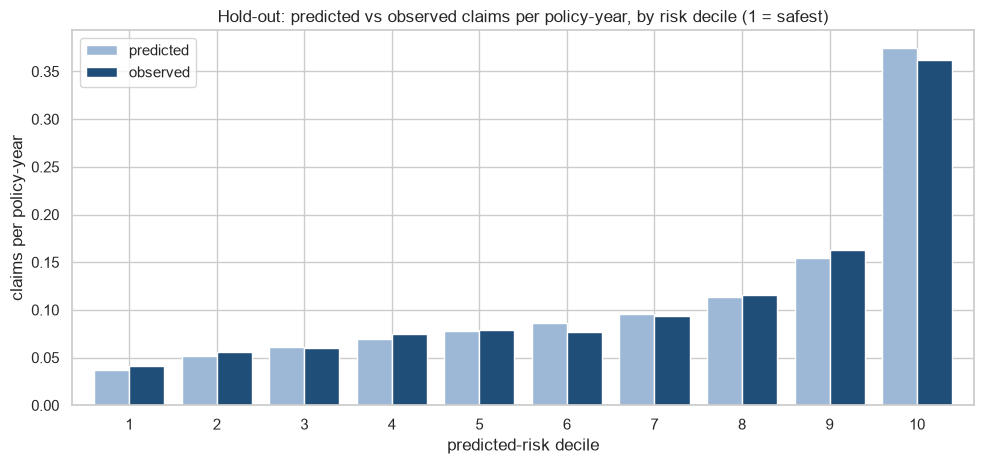

riskiest decile claims 8.7x more often than the safest (observed)


In [9]:
p = hgb.predict(Xte[feats])
t = te.assign(pred=p)
t["decile"] = pd.qcut(t["pred"].rank(method="first"), 10, labels=range(1, 11))
g = t.groupby("decile", observed=True)
lift = pd.DataFrame({"predicted": (t["pred"]*t["Exposure"]).groupby(t["decile"], observed=True).sum() / g["Exposure"].sum(),
                     "observed": g["ClaimNb"].sum() / g["Exposure"].sum()})
ax = lift.plot.bar(figsize=(10, 4.8), color=["#9db8d6", "#1f4e79"], width=.8)
ax.set_title("Hold-out: predicted vs observed claims per policy-year, by risk decile (1 = safest)")
ax.set_xlabel("predicted-risk decile"); ax.set_ylabel("claims per policy-year"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()
print("riskiest decile claims %.1fx more often than the safest (observed)" % (lift.observed.iloc[-1] / lift.observed.iloc[0]))

**Reading it.** Predicted and observed frequency rise together across deciles (the printed ratio above compares the riskiest and safest tenth on hold-out claims). That separation is what matters for pricing; individual policies remain unpredictable.

## 8. Compare with the reference approach
The reference fits a Poisson GLM with statsmodels on age, car age and region. Here is the same *style* of model (statsmodels, `Exposure` as `offset`) on our data so the coefficients can be read the same way.

In [10]:
s = tr.sample(150_000, random_state=1)
Xs = pd.get_dummies(s[["DrivAge", "VehAge", "Area"]], columns=["Area"], drop_first=True).astype(float)
Xs = sm.add_constant(Xs)
ref = sm.GLM(s["ClaimNb"], Xs, family=sm.families.Poisson(), offset=np.log(s["Exposure"])).fit()
print(ref.summary().tables[1])
mu = ref.mu
disp = ((s["ClaimNb"] - mu) ** 2 / mu).sum() / ref.df_resid
print("\nPearson dispersion = %.2f  (1 = Poisson assumption holds; clearly above 1 suggests extra variation)" % disp)
refq = sm.GLM(s["ClaimNb"], Xs, family=sm.families.Poisson(), offset=np.log(s["Exposure"])).fit(scale="X2")           # quasi-Poisson: standard errors rescaled by the dispersion
cmp_ = pd.DataFrame({"coef": ref.params, "se Poisson": ref.bse, "se quasi-Poisson": refq.bse, "z Poisson": ref.tvalues, "z quasi-Poisson": refq.tvalues, "p quasi-Poisson": refq.pvalues})
print("\nSame model with standard errors corrected for over-dispersion:"); print(cmp_.round(4).to_string())
print("\nWhat the reference article printed (1,000 rows, no exposure; I could not rerun it: its data file is no longer online):")
print(pd.DataFrame({"coef": [-0.0205, 0.0152, 0.0799, 0.0861], "p": [0.000, 0.124, 0.450, 0.427]}, index=["age_of_driver", "car_age", "region_Suburban", "region_Urban"]).to_string())

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -2.0043      0.052    -38.802      0.000      -2.106      -1.903
DrivAge       -0.0046      0.001     -5.828      0.000      -0.006      -0.003
VehAge        -0.0366      0.002    -16.224      0.000      -0.041      -0.032
Area_B         0.0384      0.046      0.834      0.404      -0.052       0.129
Area_C         0.1037      0.037      2.796      0.005       0.031       0.176
Area_D         0.2514      0.038      6.574      0.000       0.176       0.326
Area_E         0.3596      0.039      9.287      0.000       0.284       0.435
Area_F         0.4765      0.070      6.843      0.000       0.340       0.613

Pearson dispersion = 2.77  (1 = Poisson assumption holds; clearly above 1 suggests extra variation)



Same model with standard errors corrected for over-dispersion:
           coef  se Poisson  se quasi-Poisson  z Poisson  z quasi-Poisson  p quasi-Poisson
const   -2.0043      0.0517            0.0860   -38.8025         -23.3073           0.0000
DrivAge -0.0046      0.0008            0.0013    -5.8284          -3.5009           0.0005
VehAge  -0.0366      0.0023            0.0038   -16.2239          -9.7451           0.0000
Area_B   0.0384      0.0461            0.0767     0.8340           0.5009           0.6164
Area_C   0.1037      0.0371            0.0618     2.7956           1.6792           0.0931
Area_D   0.2514      0.0382            0.0637     6.5740           3.9488           0.0001
Area_E   0.3596      0.0387            0.0645     9.2872           5.5785           0.0000
Area_F   0.4765      0.0696            0.1159     6.8434           4.1106           0.0000

What the reference article printed (1,000 rows, no exposure; I could not rerun it: its data file is no longer online

**Reading it.** Same style of model on different data, partly different story. Note the limit of this comparison: **I could not rerun the reference on its own data** (its file was hosted at statso.io, which no longer resolves, and the Wayback Machine did not archive the CSV), so I compare my coefficients with the numbers the article *printed*. The article's table has no exposure and no hold-out score, and from its printed summary (ages 18-49 only, a mean of 0.675 claims per row against about 0.05 here) it looks synthetic or heavily simplified; that is my reading of the summary statistics, not a verified fact.

* **Driver age** is negative in both, as expected, but the slope is about four times smaller here (-0.0046 vs -0.0205 per year; the two models use different data, exposure treatment and age ranges, so the size is not comparable).
* **Vehicle age:** the article found a small positive, non-significant effect (+0.0152, p = 0.124); here it is negative and clearly significant (-0.0366). With 150,000 rows and the new-car spike the sign and size of a coefficient depend on the data, a reason not to rely on a 1,000-row example.
* **Region:** the article found no significant difference between rural, suburban and urban. Here the claim rate rises from area A to F (rural to urban centre).
* **Over-dispersion:** the Pearson dispersion is 2.77, so the plain Poisson standard errors are too small by about 1.7 times (the square root of 2.77). After the correction (quasi-Poisson, second table) the age and vehicle-age effects remain significant (z about -3.5 and -9.7), Areas D, E and F remain clearly higher than A, but **Area C (p = 0.09) and Area B (p = 0.6) can no longer be told apart from A**. The article mentions the Negative Binomial for this situation but never checks it. Part of the extra variation is simply risk factors this 3-variable model leaves out.

## 9. Save the model for the app

In [11]:
joblib.dump(hgb, "model/freq_hgb.joblib")
joblib.dump(glm, "model/freq_glm.joblib"); joblib.dump(glm2, "model/freq_glm_rich.joblib")
meta = {"features": feats, "overall_freq": float(df["ClaimNb"].sum()/df["Exposure"].sum()),
        "categories": {c: sorted(df[c].astype(str).unique().tolist()) for c in cat},
        "ranges": {c: [float(df[c].min()), float(df[c].max())] for c in ["DrivAge", "VehAge", "VehPower", "BonusMalus", "Density"]},
        "test_deviance": res.set_index("model")["test_deviance"].round(4).to_dict()}
json.dump(meta, open("model/meta.json", "w"), indent=1)
print(os.listdir("model"))

['freq_glm.joblib', 'freq_glm_rich.joblib', 'freq_hgb.joblib', 'meta.json']


## 10. Summary and what I would do next
* The real portfolio shows the same direction as the reference for driver age (younger drivers claim more) but also a **non-linear age effect, a new-car spike, a strong bonus-malus effect and an urban effect** that the reference's small file does not show.
* **Model ranking (test deviance, 135,603 policies):** constant 0.6274, plain GLM 0.6078 (3.1% better), richer GLM 0.5976 (4.8%), boosting 0.5783 (7.8%). About a third of the plain GLM's gap to boosting came from the GLM's weak specification; the boosting advantage over the richer GLM is 0.0193 (95% interval 0.0170 to 0.0214, paired bootstrap on one split). The GLM is easier to explain to a regulator; choose by the use case.
* The reference could not be rerun on its data (the file is no longer online); I compared with the coefficients it printed. The reference has no exposure, hold-out score or over-dispersion check.
* **Limits:** one random split; capping rules (claims at 4, exposure at 1 year) are assumptions; no claim *severity* model (a price needs frequency x average claim cost); features are policy attributes only. **Age and region are regulated or sensitive rating factors in many jurisdictions**; a real pricing model needs a legal and fairness review. Next step: a Gamma severity model on `freMTPL2sev` and a combined pure-premium estimate.